<h1> Milestone 2 (2015) </h1>

In [2]:
#imports
import pandas as pd #base kit
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, RepeatedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsRegressor #models
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.cluster import KMeans, MiniBatchKMeans, DBSCAN, AgglomerativeClustering, HDBSCAN
from scipy.cluster.hierarchy import dendrogram

random_seed = 42

In [3]:
#Removing Frame
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.bottom'] = True

<h3> Dataset Downloads </h3>

In [5]:
d15 = pd.read_csv('flights_2015.csv', low_memory = False)

<h2> Dataset 1: 2015 Flight Delays and Causes </h2>

<h3> Data Dictionary </h3>

ALL TIMES ARE IN MILITARY TIME, ARRIVAL AND DEPARTURE TIMES ARE ADJUSTED WITH LOCAL TIMEZONES

- YEAR: Year of the flight trip
- MONTH: Month of the flight trip
- DAY: Day of the flight trip
- DAY_OF_WEEK: Day of week of the flight trip
- AIRLINE: Airline identifier
- FLIGHT_NUMBER: Flight identifier
- TAIL_NUMBER: Aircrage identifier
- ORIGIN_AIRPORT: Starting airport
- DESTINATION_AIRPORT: Destination airport
- SCHEDULED_DEPARTURE: Planned departure time
- DEPARTURE_TIME: WHEELS_OFF - TAXI_OUT
- DEPARTURE_DELAY: Total delay on departure (minutes)
- TAXI_OUT: Time duration elapsed between the origin airport gate and wheels off (minutes)
- WHEELS_OFF: The time point that the aircraft's wheels leave the ground
- SCHEDULED_TIME: Planned time amount for the flight trip
- ELAPSED_TIME: TAXI_OUT + AIR_TIME + TAXI_IN (minutes)
- AIR TIME: Time duration between WHEELS_OFF and WHEELS_ON times (minutes)
- DISTANCE: Distance between 2 airports (miles)
- WHEELS_ON: The time point that the aircraft's wheels touch on the ground
- TAXI_IN: The time duration elapsed between wheels-on and gate arrival at the destination airport (minutes)
- SCHEDULED_ARRIVAL: Arrival time
- ARRIVAL_TIME: WHEELS_ON + TAXI_IN
- ARRIVAL_DELAY: WHEELS_ON + TAXI_IN - SCHEDULED_ARRIVAL (minutes; if this value is positive, that means the flight got in early)
- DIVERTED: Aircraft landed on airport that out of schedule (0 or 1)
- CANCELLED: Flight Cancelled (1 = cancelled)
- CANCELLATION_REASON: Reason for Cancellation of flight: A - Airline/Carrier; B - Weather; C - National Air System; D - Security
- AIR_SYSTEM_DELAY: Delay caused by air system (minutes)
- SECURITY_DELAY: Delay caused by security (minutes)
- AIRLINE_DELAY: Delay caused by the airline (minutes)
- LATE_AIRCRAFT_DELAY: Delay caused by aircraft (minutes)
- WEATHER_DELAY: Delay caused by weather (minutes)

<h3> Preprocessing </h3>

In [10]:
all15 = d15.copy()

In [11]:
all15.head(5)

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


<h3> Duplicate Rows, Missing Values </h3>

In [13]:
dupes_15 = all15[all15.duplicated()]
dupes_15

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY


<h3> Dummy-ing the null values in delay reason columns </h3>

In [15]:
all15[['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']] = all15[['AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']].fillna(0)

<h3> Adding Full Names for Airlines (Important Later)</h3>

In [17]:
#mapping the airline abbreviations to full names

airline_map = {'UA': 'United Air Lines Inc.',
 'AA': 'American Airlines Inc.',
 'US': 'US Airways Inc.',
 'F9': 'Frontier Airlines Inc.',
 'B6': 'JetBlue Airways',
 'OO': 'Skywest Airlines Inc.',
 'AS': 'Alaska Airlines Inc.',
 'NK': 'Spirit Air Lines',
 'WN': 'Southwest Airlines Co.',
 'DL': 'Delta Air Lines Inc.',
 'EV': 'Atlantic Southeast Airlines',
 'HA': 'Hawaiian Airlines Inc.',
 'MQ': 'American Eagle Airlines Inc.',
 'VX': 'Virgin America'}

In [18]:
# Create new column 'Category' based on 'ID'
all15['AIRLINE_FULL'] = all15['AIRLINE'].map(airline_map)

In [19]:
all15.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,AIRLINE_FULL
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,-22.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,-9.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,5.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,US Airways Inc.
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,-9.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,-21.0,0,0,NaN,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.


<h3> What's going on w/ the canceled flights? </h3>

In [21]:
section = all15[all15['CANCELLATION_REASON'].notnull() & all15['CANCELLED'] == 1]
len(section)

89884

All cancelled flights will have a non-null cancellation reason.

In [23]:
len(all15) - len(section) #every flight with a null cancellation reason wasn't cancelled

5729195

In [24]:
all15['CANCELLATION_REASON'] = all15['CANCELLATION_REASON'].fillna('Not Canceled')

<h3> Null Tail Numbers </h3>

In [26]:
section = all15[all15['TAIL_NUMBER'].isnull()]
section.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14721 entries, 297 to 5818157
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 14721 non-null  int64  
 1   MONTH                14721 non-null  int64  
 2   DAY                  14721 non-null  int64  
 3   DAY_OF_WEEK          14721 non-null  int64  
 4   AIRLINE              14721 non-null  object 
 5   FLIGHT_NUMBER        14721 non-null  int64  
 6   TAIL_NUMBER          0 non-null      object 
 7   ORIGIN_AIRPORT       14721 non-null  object 
 8   DESTINATION_AIRPORT  14721 non-null  object 
 9   SCHEDULED_DEPARTURE  14721 non-null  int64  
 10  DEPARTURE_TIME       0 non-null      float64
 11  DEPARTURE_DELAY      0 non-null      float64
 12  TAXI_OUT             0 non-null      float64
 13  WHEELS_OFF           0 non-null      float64
 14  SCHEDULED_TIME       14721 non-null  float64
 15  ELAPSED_TIME         0 non-null      

Flights with no tail number appear to be cancelled flights.

In [28]:
all15['TAIL_NUMBER'] = all15['TAIL_NUMBER'].fillna('No Tail')

<h3> Null Values for Scheduled Time </h3>

In [30]:
section = all15[all15['SCHEDULED_TIME'].isnull()][['SCHEDULED_TIME', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON']]
section

,SCHEDULED_TIME,DIVERTED,CANCELLED,CANCELLATION_REASON
483174,NaN,0,1,B
619941,NaN,0,1,B
1720237,NaN,1,0,Not Canceled
1820960,NaN,0,1,B
2031482,NaN,0,1,B
2034453,NaN,0,1,C


Of the 6 flights with null scheduled time, 5 were canceled and 1 was diverted. I'm down to drop them.

In [32]:
all15 = all15.dropna(subset=['SCHEDULED_TIME'])

<h3>EQUAL Null Values for (Presumedly) Canceled Flights </h3>

In [34]:
# pulling the null values we're seeing for cancelled flights

cancel = all15[all15['CANCELLED'] == 1][['DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT',
                                         'WHEELS_OFF', 'ELAPSED_TIME', 'AIR_TIME',
                                         'WHEELS_ON', 'TAXI_IN', 'ARRIVAL_TIME',
                                         'ARRIVAL_DELAY']]
cancel.head()

,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,ELAPSED_TIME,AIR_TIME,WHEELS_ON,TAXI_IN,ARRIVAL_TIME,ARRIVAL_DELAY
32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
42,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
#finding values in this section that aren't null

section = cancel.notnull()
len(section)

89879

So here's what we have at this point:

- cancelled flights have no value departure time or departure delay, or most of the other variables pertaining to the flight

ngl I think we need to just separate the cancelled and non-cancelled flights

In [37]:
all15 = all15.dropna(subset=['SCHEDULED_TIME'])

<h3>Splitting up Cancelled and not cancelled flights</h3>

In [39]:
all15_nc = all15[all15.CANCELLED == 0]
all15_c = all15[all15.CANCELLED == 1]

In [40]:
print('Checking the columns for null values:')
print()

for col in all15_nc:
        rows_with_null = all15_nc[all15_nc[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 0
DEPARTURE_DELAY 0
TAXI_OUT 0
WHEELS_OFF 0
SCHEDULED_TIME 0
ELAPSED_TIME 15186
AIR_TIME 15186
DISTANCE 0
WHEELS_ON 2628
TAXI_IN 2628
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 2628
ARRIVAL_DELAY 15186
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
AIRLINE_FULL 0


In [41]:
print('Checking the columns for null values:')
print()

for col in all15_c:
        rows_with_null = all15_c[all15_c[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 86153
DEPARTURE_DELAY 86153
TAXI_OUT 89047
WHEELS_OFF 89047
SCHEDULED_TIME 0
ELAPSED_TIME 89879
AIR_TIME 89879
DISTANCE 0
WHEELS_ON 89879
TAXI_IN 89879
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 89879
ARRIVAL_DELAY 89879
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
AIRLINE_FULL 0


In [42]:
# dropping nulls from non-cancelled flights (15186 out of over 5 million rows, negligible)

all15_nc = all15_nc.dropna()

print('Checking the columns for null values:')
print()

for col in all15_nc:
        rows_with_null = all15_nc[all15_nc[col].isnull()]
        print(col, len(rows_with_null))

Checking the columns for null values:

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
DEPARTURE_TIME 0
DEPARTURE_DELAY 0
TAXI_OUT 0
WHEELS_OFF 0
SCHEDULED_TIME 0
ELAPSED_TIME 0
AIR_TIME 0
DISTANCE 0
WHEELS_ON 0
TAXI_IN 0
SCHEDULED_ARRIVAL 0
ARRIVAL_TIME 0
ARRIVAL_DELAY 0
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIR_SYSTEM_DELAY 0
SECURITY_DELAY 0
AIRLINE_DELAY 0
LATE_AIRCRAFT_DELAY 0
WEATHER_DELAY 0
AIRLINE_FULL 0


In [43]:
#keeping just the cancellation info for the canceled flights

all15_c = all15_c.drop(['DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'ELAPSED_TIME',
                       'AIR_TIME', 'WHEELS_ON', 'TAXI_IN', 'ARRIVAL_TIME', 'ARRIVAL_DELAY',
                       'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY'], axis = 1)

for col in all15_c:
        rows_with_null = all15_c[all15_c[col].isnull()]
        print(col, len(rows_with_null))

YEAR 0
MONTH 0
DAY 0
DAY_OF_WEEK 0
AIRLINE 0
FLIGHT_NUMBER 0
TAIL_NUMBER 0
ORIGIN_AIRPORT 0
DESTINATION_AIRPORT 0
SCHEDULED_DEPARTURE 0
SCHEDULED_TIME 0
DISTANCE 0
SCHEDULED_ARRIVAL 0
DIVERTED 0
CANCELLED 0
CANCELLATION_REASON 0
AIRLINE_FULL 0


First preprocessing steps:

- Dummied down the variables for different types of delays
- Labeled flights with no tail numbers
- Dropped rows with no SCHEDULED_TIME (projected trip time)
- Created a TOTAL_DELAY column (elapsed_time - scheduled time)
- Split up cancelled and non-cancelled flights (instead of merging them with another one)
- Non-cancelled: dropped nulls, 15186 rows
- Cancelled: dropped irrelevant columns (cancelled flights aren't delayed fam)

<h3> Encoding Categorical Variables</h3>

In [46]:
#for non-cancelled first

cat_15nc = all15_nc.select_dtypes(include=['object'])
cat_15nc

,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON,AIRLINE_FULL
0,AS,N407AS,ANC,SEA,Not Canceled,Alaska Airlines Inc.
1,AA,N3KUAA,LAX,PBI,Not Canceled,American Airlines Inc.
2,US,N171US,SFO,CLT,Not Canceled,US Airways Inc.
3,AA,N3HYAA,LAX,MIA,Not Canceled,American Airlines Inc.
4,AS,N527AS,SEA,ANC,Not Canceled,Alaska Airlines Inc.
...,...,...,...,...,...,...
5819074,B6,N657JB,LAX,BOS,Not Canceled,JetBlue Airways
5819075,B6,N828JB,JFK,PSE,Not Canceled,JetBlue Airways
5819076,B6,N913JB,JFK,SJU,Not Canceled,JetBlue Airways
5819077,B6,N527JB,MCO,SJU,Not Canceled,JetBlue Airways


In [47]:
cat_15c = all15_c.select_dtypes(include=['object'])
cat_15c

,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON,AIRLINE_FULL
32,AS,N431AS,ANC,SEA,A,Alaska Airlines Inc.
42,AA,N3BDAA,PHX,DFW,B,American Airlines Inc.
68,OO,N746SK,MAF,IAH,B,Skywest Airlines Inc.
82,MQ,N660MQ,SGF,DFW,B,American Eagle Airlines Inc.
90,OO,N583SW,RDD,SFO,A,Skywest Airlines Inc.
...,...,...,...,...,...,...
5818090,UA,No Tail,IAH,TPA,A,United Air Lines Inc.
5818157,UA,No Tail,SFO,LAX,A,United Air Lines Inc.
5818318,AA,N880AA,MIA,SAN,A,American Airlines Inc.
5818777,NK,N522NK,FLL,IAG,A,Spirit Air Lines


In [48]:
len(pd.unique(cat_15c.TAIL_NUMBER))

3846

In [49]:
#encoding the cancellation reasons for cancelled flights

cancels = pd.get_dummies(all15_c['CANCELLATION_REASON'], prefix = 'CANCELLATION', dtype = int)
all15_c = all15_c.join(cancels)
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,DISTANCE,SCHEDULED_ARRIVAL,DIVERTED,CANCELLED,CANCELLATION_REASON,AIRLINE_FULL,CANCELLATION_A,CANCELLATION_B,CANCELLATION_C,CANCELLATION_D
32,2015,1,1,4,AS,136,N431AS,ANC,SEA,135,...,1448,600,0,1,A,Alaska Airlines Inc.,1,0,0,0
42,2015,1,1,4,AA,2459,N3BDAA,PHX,DFW,200,...,868,500,0,1,B,American Airlines Inc.,0,1,0,0
68,2015,1,1,4,OO,5254,N746SK,MAF,IAH,510,...,429,637,0,1,B,Skywest Airlines Inc.,0,1,0,0
82,2015,1,1,4,MQ,2859,N660MQ,SGF,DFW,525,...,364,700,0,1,B,American Eagle Airlines Inc.,0,1,0,0
90,2015,1,1,4,OO,5460,N583SW,RDD,SFO,530,...,199,700,0,1,A,Skywest Airlines Inc.,1,0,0,0


In [50]:
#renaming them

all15_c['CANCELLATION_AIRLINE'] = all15_c['CANCELLATION_A']
all15_c['CANCELLATION_WEATHER'] = all15_c['CANCELLATION_B']
all15_c['CANCELLATION_SYSTEM'] = all15_c['CANCELLATION_C']
all15_c['CANCELLATION_SECURITY'] = all15_c['CANCELLATION_D']

all15_c = all15_c.drop(['CANCELLATION_A', 'CANCELLATION_B', 'CANCELLATION_C', 'CANCELLATION_D'], axis = 1)
all15_c.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,DISTANCE,SCHEDULED_ARRIVAL,DIVERTED,CANCELLED,CANCELLATION_REASON,AIRLINE_FULL,CANCELLATION_AIRLINE,CANCELLATION_WEATHER,CANCELLATION_SYSTEM,CANCELLATION_SECURITY
32,2015,1,1,4,AS,136,N431AS,ANC,SEA,135,...,1448,600,0,1,A,Alaska Airlines Inc.,1,0,0,0
42,2015,1,1,4,AA,2459,N3BDAA,PHX,DFW,200,...,868,500,0,1,B,American Airlines Inc.,0,1,0,0
68,2015,1,1,4,OO,5254,N746SK,MAF,IAH,510,...,429,637,0,1,B,Skywest Airlines Inc.,0,1,0,0
82,2015,1,1,4,MQ,2859,N660MQ,SGF,DFW,525,...,364,700,0,1,B,American Eagle Airlines Inc.,0,1,0,0
90,2015,1,1,4,OO,5460,N583SW,RDD,SFO,530,...,199,700,0,1,A,Skywest Airlines Inc.,1,0,0,0


In [51]:
all15_nc = all15_nc.drop(['CANCELLED', 'CANCELLATION_REASON'], axis = 1)
all15_nc.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5714008 entries, 0 to 5819078
Data columns (total 30 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              object 
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          object 
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24  AIR

In [52]:
all15_c.info()

<class 'pandas.core.frame.DataFrame'>
Index: 89879 entries, 32 to 5818843
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   YEAR                   89879 non-null  int64  
 1   MONTH                  89879 non-null  int64  
 2   DAY                    89879 non-null  int64  
 3   DAY_OF_WEEK            89879 non-null  int64  
 4   AIRLINE                89879 non-null  object 
 5   FLIGHT_NUMBER          89879 non-null  int64  
 6   TAIL_NUMBER            89879 non-null  object 
 7   ORIGIN_AIRPORT         89879 non-null  object 
 8   DESTINATION_AIRPORT    89879 non-null  object 
 9   SCHEDULED_DEPARTURE    89879 non-null  int64  
 10  SCHEDULED_TIME         89879 non-null  float64
 11  DISTANCE               89879 non-null  int64  
 12  SCHEDULED_ARRIVAL      89879 non-null  int64  
 13  DIVERTED               89879 non-null  int64  
 14  CANCELLED              89879 non-null  int64  
 15  CANC

Second set of preprocessing steps:

- Encoded the 4 cancellation reasons

We kept the original variables because we can use those for barplots later

<h3>Creating DATE Column</h3>

In [55]:
#creating binary variable from what we have 

all15_nc['IS_SW'] = [1 if i == 'WN' else 0 for i in all15_nc.AIRLINE]

In [56]:
all15_nc['DATE'] = pd.to_datetime(all15_nc[['YEAR', 'MONTH', 'DAY']])
all15_c['DATE'] = pd.to_datetime(all15_c[['YEAR', 'MONTH', 'DAY']])

In [57]:
all15_nc.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_DELAY,DIVERTED,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,AIRLINE_FULL,IS_SW,DATE
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,-22.0,0,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.,0,2015-01-01
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,-9.0,0,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.,0,2015-01-01
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,5.0,0,0.0,0.0,0.0,0.0,0.0,US Airways Inc.,0,2015-01-01
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,-9.0,0,0.0,0.0,0.0,0.0,0.0,American Airlines Inc.,0,2015-01-01
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,-21.0,0,0.0,0.0,0.0,0.0,0.0,Alaska Airlines Inc.,0,2015-01-01


Last set of preprocessing (2015):

- Changed CANCELLATION_REASON from coded letter to the actual reason (below)
- Created datetime column from YEAR, MONTH, and DAY

Non-Cancelled Flights: 5714008 flights
Cancelled Flights: 89879 flights

Keeping the correlation matrix for reference

In [60]:
number15= all15_nc.drop(['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'FLIGHT_NUMBER', 'AIRLINE', 'AIRLINE_FULL',
                         'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE',
                        'DEPARTURE_TIME', 'WHEELS_OFF', 'WHEELS_ON', 'SCHEDULED_ARRIVAL',
                        'ARRIVAL_TIME', 'DATE', 'DIVERTED'], axis =1) #creating df of numeric columns only to run correlation matrix

corrs = number15.corr()

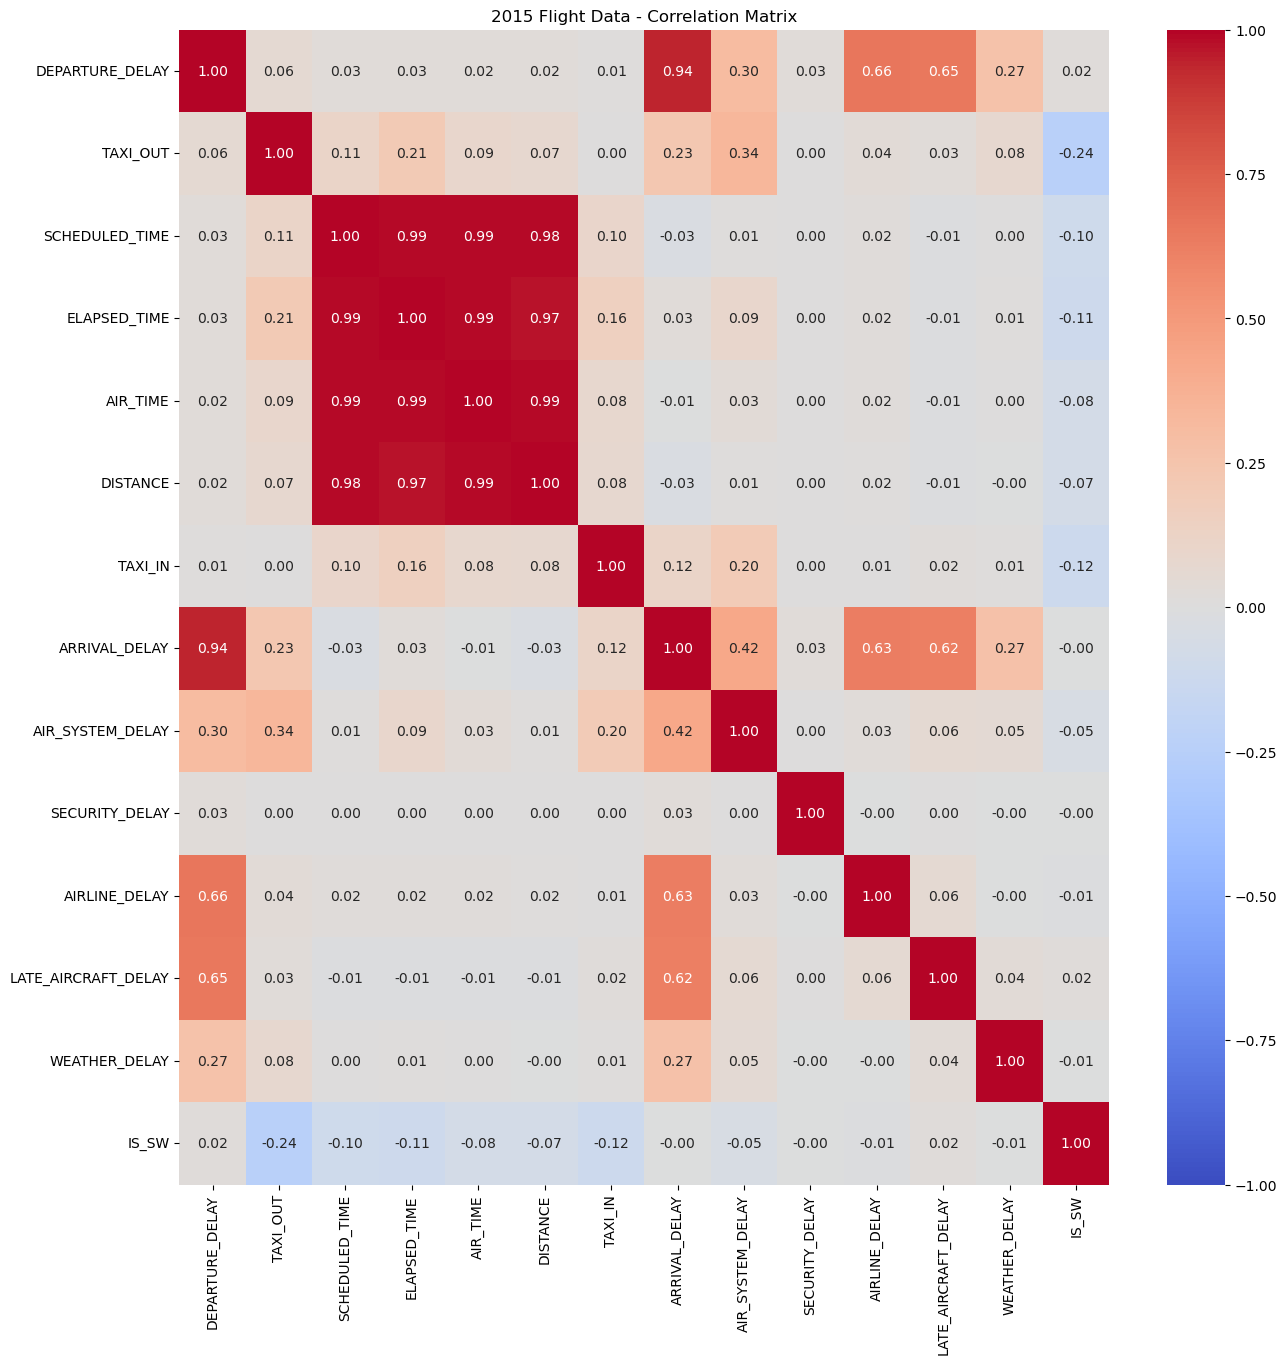

In [61]:
plt.figure(figsize=(15, 15))

# Making a heatmap
sns.heatmap(corrs,
            annot=True,     # Annotate each cell with the correlation value
            fmt=".2f",      # Set the annotation format to two decimal places
            cmap='coolwarm',# Choose a divergent color map
            vmin=-1, vmax=1,# Ensure the color scale ranges from -1 to 1
            center=0        # Center the color map at 0
           )

# Display the plot
plt.title('2015 Flight Data - Correlation Matrix')
plt.show()

What we know:

- Arrival and Departure delay seem to be almost perfectly correlated (makes sense)
- Our created target variable TOTAL_DELAY: 2 highest positive correlations are with TAXI_OUT (0.53) and AIR_SYSTEM_DELAY (0.42)
- The original target variables: ARRIVAL_DELAY highly correlated with AIRLINE_DELAY (0.63) and LATE_AIRCRAFT_DELAY (0.62), DEPARTURE_DELAY highly correlated with AIRLINE_DELAY (0.66) and LATE_AIRCRAFT_DELAY (0.65)
- Distance not highly correlated with anything
- None of the encoded airline variables are super strongly correlated with our targets

In [63]:
#standard scaling the numerical data

sc = StandardScaler()

sc15 = sc.fit_transform(number15)
df_scaled = pd.DataFrame(sc15, columns=number15.columns)
df_scaled.head()

,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,TAXI_IN,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,IS_SW
0,-0.550149,0.555534,0.837906,0.767996,0.768209,1.024449,-0.610268,-0.672426,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
1,-0.468826,-0.457700,1.833737,1.913378,2.069593,2.473529,-0.610268,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
2,-0.306179,-0.007374,1.913403,2.102029,2.111126,2.417669,0.635517,0.015099,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
3,-0.387502,-0.119955,1.900125,1.940328,2.000370,2.493245,0.101609,-0.341396,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
4,-0.279071,-0.570282,1.236238,1.050973,1.183544,1.024449,-0.432298,-0.646963,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108


In [64]:
#making a sample of the scaled dataset to run the cross validation for the models (whole thing is too large and will likely crash the server)

sampled_df = df_scaled.sample(frac=0.1)
supersampled_df = df_scaled.sample(frac=0.005)

In [65]:
sampled_df.head()

,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,TAXI_IN,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,IS_SW
203654,-0.360394,0.668116,0.067797,0.336794,0.339029,-0.211048,-0.966206,0.167882,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
3972118,-0.116424,0.217789,-0.821812,-0.727738,-0.740842,-0.753221,-0.432298,0.091490,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
4770915,-0.306179,0.442952,-0.728868,-0.727738,-0.782376,-0.758150,-0.254329,-0.265004,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
529034,-0.279071,-0.345119,0.505962,0.350269,0.435941,0.360698,-0.432298,-0.570571,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,1.897145
5012722,-0.306179,0.217789,2.298458,2.425431,2.498772,1.974073,-0.432298,-0.112221,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,1.897145


In [66]:
supersampled_df.head()

,DEPARTURE_DELAY,TAXI_OUT,SCHEDULED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,TAXI_IN,ARRIVAL_DELAY,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,IS_SW
14648,-0.197747,-0.007374,-0.064981,0.053817,0.062139,0.122470,-0.076360,0.040563,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
5197389,-0.523041,-0.795445,-1.220145,-1.037665,-0.948510,-1.044023,-0.254329,-0.112221,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
1777777,1.184752,0.105208,-0.981145,-0.889439,-0.893132,-0.853441,-0.432298,1.313757,0.037288,-0.015319,-0.160111,-0.21049,5.902202,-0.527108
4024915,-0.360394,-0.119955,-0.954590,-0.956814,-0.920821,-0.978305,-0.610268,-0.315932,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108
4055611,-0.333286,0.217789,1.302627,1.374375,1.405056,1.257748,-0.254329,-0.214076,-0.190485,-0.015319,-0.160111,-0.21049,-0.061046,-0.527108


In [67]:
#grabbing the features the selection picked

fwd_vars = ['TAXI_OUT',
 'AIR_SYSTEM_DELAY',
 'AIRLINE_DELAY',
 'LATE_AIRCRAFT_DELAY',
 'WEATHER_DELAY']
fwd_vars

['TAXI_OUT',
 'AIR_SYSTEM_DELAY',
 'AIRLINE_DELAY',
 'LATE_AIRCRAFT_DELAY',
 'WEATHER_DELAY']

In [68]:
#set our x_train and y_train (fwd selected vars, departure delay time for y)

X_train, X_test, y_train, y_test = train_test_split(sampled_df[fwd_vars], sampled_df.DEPARTURE_DELAY,
                                                    test_size=0.25, random_state=random_seed)

In [69]:
len(X_test), len(supersampled_df)

(142851, 28570)

<h3>K Nearest Neighbors</h3>

In [116]:
#performing cross_validation to find optimal K

from sklearn.model_selection import GridSearchCV, RepeatedKFold

repeated_cv = RepeatedKFold(n_splits     = 3, 
                            n_repeats    = 1,
                            random_state = random_seed
                           )     

# Define a search space for K (e.g., from 1 to 30)
param_grid = {'n_neighbors': range(1, 16)}

# Setup the regressor
knb = KNeighborsRegressor()

# Perform cross validation
grid_search = GridSearchCV(knb, param_grid, cv=repeated_cv,
                           scoring='neg_root_mean_squared_error', 
                           n_jobs = -1,
                           verbose = 1)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


GridSearchCV(cv=RepeatedKFold(n_repeats=1, n_splits=3, random_state=42),
             estimator=KNeighborsRegressor(), n_jobs=-1,
             param_grid={'n_neighbors': range(1, 16)},
             scoring='neg_root_mean_squared_error', verbose=1)

In [120]:
results = pd.DataFrame(grid_search.cv_results_)

# Convert negative RMSE to positive
results['mean_test_RMSE'] = -results['mean_test_score']
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,mean_test_RMSE
0,0.284739,0.019177,121.220520,0.572056,1,{'n_neighbors': 1},-0.303000,-0.331250,-0.300370,-0.311540,0.013978,15,0.311540
1,0.278750,0.020935,121.364892,0.431466,2,{'n_neighbors': 2},-0.261990,-0.292835,-0.267830,-0.274218,0.013378,14,0.274218
2,0.204817,0.060768,120.059523,1.698478,3,{'n_neighbors': 3},-0.266715,-0.275921,-0.254695,-0.265777,0.008691,13,0.265777
3,0.106125,0.001288,117.493057,1.102778,4,{'n_neighbors': 4},-0.254219,-0.261777,-0.247133,-0.254376,0.005979,12,0.254376
4,0.099282,0.001816,117.731799,1.313845,5,{'n_neighbors': 5},-0.248054,-0.249111,-0.244155,-0.247107,0.002131,11,0.247107
5,0.106958,0.020970,118.961928,2.117778,6,{'n_neighbors': 6},-0.246657,-0.249809,-0.242215,-0.246227,0.003115,10,0.246227
6,0.098039,0.005154,120.217695,0.289261,7,{'n_neighbors': 7},-0.240034,-0.247815,-0.244063,-0.243971,0.003177,9,0.243971
7,0.085109,0.004593,120.257091,0.125209,8,{'n_neighbors': 8},-0.239939,-0.246312,-0.239220,-0.241824,0.003187,8,0.241824
8,0.094172,0.010399,116.884208,0.160093,9,{'n_neighbors': 9},-0.238450,-0.242955,-0.237259,-0.239555,0.002453,7,0.239555
9,0.077867,0.008440,117.377350,0.801876,10,{'n_neighbors': 10},-0.237692,-0.240484,-0.236473,-0.238216,0.001679,2,0.238216


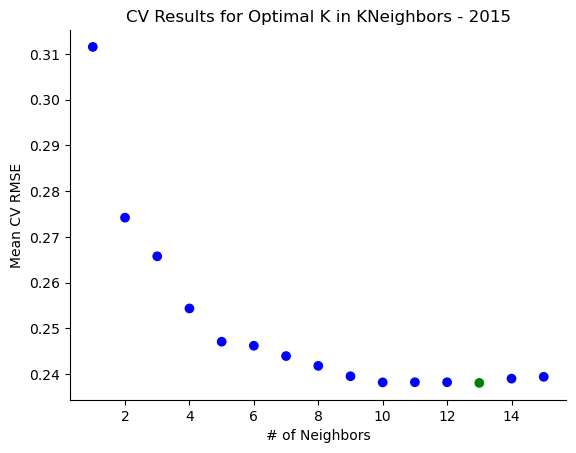

In [122]:
# Create a list filled with the default color
colors = ['blue'] * len(results)

# Change the color of the specific index (e.g., index 3)
colors[12] = 'green'

plt.scatter(results.param_n_neighbors, results.mean_test_RMSE, color = colors)
plt.xlabel('# of Neighbors')
plt.ylabel('Mean CV RMSE')
plt.title('CV Results for Optimal K in KNeighbors - 2015')
plt.show()

In [124]:
# Output the best K
print(f"Optimal K: {grid_search.best_params_['n_neighbors']}")

Optimal K: 13


In [126]:
final_knb = KNeighborsRegressor(n_neighbors = 13)
final_knb.fit(X_train, y_train)

KNeighborsRegressor(n_neighbors=13)

In [128]:
y_preds = final_knb.predict(X_test)
test_RMSE = root_mean_squared_error(y_test, y_preds)
print('RMSE of our optimized KNN on the test set:', f"{test_RMSE:.3f}")

RMSE of our optimized KNN on the test set: 0.237


<h3>Gradient Boost</h3>

In [130]:
# Define the parameter grid
param_dist = {
     'n_estimators': range(100, 110),
     'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2], 
     'max_depth' : range(1, 6),
     'min_samples_leaf': range(1, 6)
}

# Setup the regressor
gb = GradientBoostingRegressor()

# Perform cross validation
ran_search = RandomizedSearchCV(gb, param_dist, cv=repeated_cv,
                           scoring='neg_root_mean_squared_error', 
                           n_jobs = -1,
                           verbose = 1)

ran_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


RandomizedSearchCV(cv=RepeatedKFold(n_repeats=1, n_splits=3, random_state=42),
                   estimator=GradientBoostingRegressor(), n_jobs=-1,
                   param_distributions={'learning_rate': [0.01, 0.05, 0.1, 0.15,
                                                          0.2],
                                        'max_depth': range(1, 6),
                                        'min_samples_leaf': range(1, 6),
                                        'n_estimators': range(100, 110)},
                   scoring='neg_root_mean_squared_error', verbose=1)

In [132]:
results = pd.DataFrame(ran_search.cv_results_)

# Convert negative RMSE to positive
results['mean_test_RMSE'] = -results['mean_test_score']
results = results.sort_values(by = 'mean_test_RMSE')
results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_estimators,param_min_samples_leaf,param_max_depth,param_learning_rate,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score,mean_test_RMSE
3,9.128044,0.099068,0.090649,0.001847,105,1,4,0.15,"{'n_estimators': 105, 'min_samples_leaf': 1, '...",-0.228060,-0.221566,-0.224071,-0.224566,0.002674,1,0.224566
9,6.106724,1.554175,0.055730,0.008708,101,1,3,0.20,"{'n_estimators': 101, 'min_samples_leaf': 1, '...",-0.226033,-0.224130,-0.227888,-0.226017,0.001534,2,0.226017
6,10.667494,0.161011,0.087550,0.009019,100,1,5,0.20,"{'n_estimators': 100, 'min_samples_leaf': 1, '...",-0.229716,-0.221806,-0.226802,-0.226108,0.003267,3,0.226108
8,10.030147,0.348523,0.074346,0.003263,103,2,5,0.15,"{'n_estimators': 103, 'min_samples_leaf': 2, '...",-0.230284,-0.221674,-0.226513,-0.226157,0.003524,4,0.226157
1,11.024115,0.075203,0.104295,0.002821,105,4,5,0.10,"{'n_estimators': 105, 'min_samples_leaf': 4, '...",-0.229973,-0.223089,-0.228247,-0.227103,0.002924,5,0.227103
0,4.874087,0.018843,0.053084,0.001904,100,3,2,0.15,"{'n_estimators': 100, 'min_samples_leaf': 3, '...",-0.233184,-0.230483,-0.229116,-0.230928,0.001691,6,0.230928
5,2.990388,0.098692,0.027249,0.001874,101,1,1,0.15,"{'n_estimators': 101, 'min_samples_leaf': 1, '...",-0.288285,-0.286186,-0.276024,-0.283498,0.005354,7,0.283498
7,2.761451,0.009019,0.026268,0.000787,100,4,1,0.05,"{'n_estimators': 100, 'min_samples_leaf': 4, '...",-0.503496,-0.491602,-0.477796,-0.490965,0.010502,8,0.490965
2,5.257101,0.101507,0.059755,0.001822,108,5,2,0.01,"{'n_estimators': 108, 'min_samples_leaf': 5, '...",-0.647373,-0.627383,-0.622216,-0.632324,0.010848,9,0.632324
4,5.332841,0.077153,0.055545,0.003537,108,3,2,0.01,"{'n_estimators': 108, 'min_samples_leaf': 3, '...",-0.647373,-0.627383,-0.622216,-0.632324,0.010848,9,0.632324


In [134]:
# Output the best params
print(f"Optimal Parameters: {ran_search.best_params_}")

Optimal Parameters: {'n_estimators': 105, 'min_samples_leaf': 1, 'max_depth': 4, 'learning_rate': 0.15}


In [138]:
final_gb = GradientBoostingRegressor(n_estimators = ran_search.best_params_['n_estimators'],
                                    min_samples_leaf = ran_search.best_params_['min_samples_leaf'],
                                    max_depth = ran_search.best_params_['max_depth'],
                                    learning_rate = ran_search.best_params_['learning_rate'])
final_gb.fit(X_train, y_train)
importances = final_gb.feature_importances_

In [140]:
gb_importances = pd.Series(importances, index=fwd_vars)
g_imp = gb_importances.sort_values(ascending = False)
g_imp

LATE_AIRCRAFT_DELAY    0.449381
AIRLINE_DELAY          0.414274
AIR_SYSTEM_DELAY       0.073681
WEATHER_DELAY          0.056455
TAXI_OUT               0.006209
dtype: float64

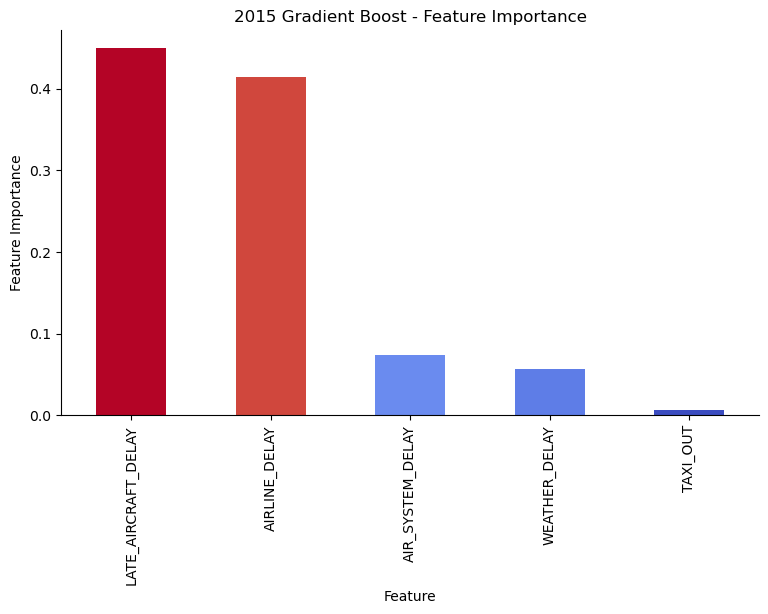

In [142]:
# Generate the bar plot
plt.figure(figsize=(9, 5))
# 1. Normalize values to [0, 1] for the colormap
norm = plt.Normalize(g_imp.min(), g_imp.max())

# 2. Choose a colormap (e.g., 'viridis', 'plasma', 'coolwarm')
cmap = plt.get_cmap('coolwarm')

# 3. Map values to colors
colors = cmap(norm(g_imp))

g_imp.plot.bar(color = colors, title='2015 Gradient Boost - Feature Importance')
plt.xlabel('Feature')
plt.ylabel('Feature Importance');

In [144]:
y_preds = final_gb.predict(X_test)
test_RMSE = root_mean_squared_error(y_test, y_preds)
print('RMSE of our optimized GB on the test set:', f"{test_RMSE:.3f}")

RMSE of our optimized GB on the test set: 0.225


<h3>Clustering - KMeans</H3>

In [193]:
fwd_vars_C = fwd_vars + ['DEPARTURE_DELAY']
fwd_vars_C

['TAXI_OUT',
 'AIR_SYSTEM_DELAY',
 'AIRLINE_DELAY',
 'LATE_AIRCRAFT_DELAY',
 'WEATHER_DELAY',
 'DEPARTURE_DELAY']

In [195]:
X_trainC, X_testC = train_test_split(sampled_df[fwd_vars_C], test_size=0.25, random_state=random_seed)

In [197]:
len(X_testC)

142851

In [199]:
# starting w/ Mini Batch K-means immediately batch_size determines how many rows are processed at a once

mb_kmeans = MiniBatchKMeans(n_clusters=2, batch_size=2000, random_state=random_seed)

mb_kmeans.fit(X_trainC)

MiniBatchKMeans(batch_size=2000, n_clusters=2, random_state=42)

In [201]:
labels = mb_kmeans.fit_predict(X_trainC)
score = silhouette_score(X_trainC, labels, sample_size=2000, random_state=42)
print(f"Mini-Batch K-Means Silhouette Score: {score:.4f}")

Mini-Batch K-Means Silhouette Score: 0.8135


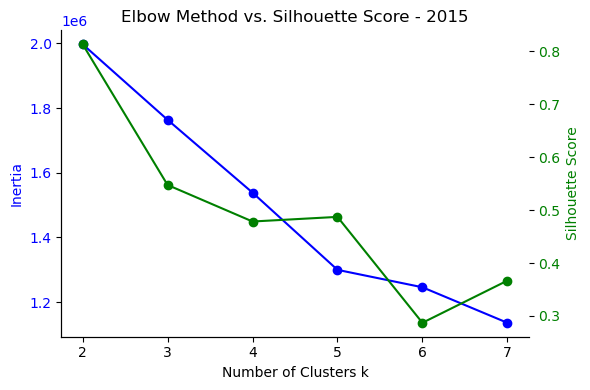

In [203]:
#the inertia feature is the WCSS. optimizing our K value

wcss = []
sil = []

k_range = range(2, 8)

for k in k_range:
    mb_k = MiniBatchKMeans(n_clusters=k, batch_size=2000, random_state=random_seed)
    mb_k.fit(X_trainC)

    # .inertia_ returns the WCSS score for the fitted model
    wcss.append(mb_k.inertia_)

    #generating a silhouette score for the model
    labels = mb_k.fit_predict(X_trainC)
    sil.append(silhouette_score(X_trainC, labels, sample_size=2000, random_state=random_seed))

#Graphing Station
fig, ax1 = plt.subplots(figsize=(6, 4))

# Primary y-axis: Inertia (Elbow Method)
ax1.plot(k_range, wcss, 'bo-', label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters k')
ax1.set_ylabel('Inertia', color='b')
ax1.tick_params(axis='y', labelcolor='b')

# Secondary y-axis: Silhouette Score
ax2 = ax1.twinx()
ax2.plot(k_range, sil, 'go-', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='g')
ax2.tick_params(axis='y', labelcolor='g')

# Title and layout
plt.title('Elbow Method vs. Silhouette Score - 2015')
fig.tight_layout()
plt.show()

In [205]:
#looks like optimal K is 5 by WCSS, 2 by silhouette score

mb_opt = MiniBatchKMeans(n_clusters=5, batch_size=2000, random_state=random_seed)

mb_opt.fit(X_trainC)

labels = mb_opt.fit_predict(X_trainC)
score = silhouette_score(X_trainC, labels, sample_size=5000, random_state=random_seed)
print(f"Optimized Mini-Batch K-Means Silhouette Score: {score:.4f}")

Optimized Mini-Batch K-Means Silhouette Score: 0.4718


In [207]:
X_trainC['MBK_Cluster'] = labels

In [209]:
X_trainC.groupby(['MBK_Cluster']).mean()

,TAXI_OUT,AIR_SYSTEM_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,DEPARTURE_DELAY
MBK_Cluster,,,,,,
0,1.198704,0.120117,-0.044829,-0.105819,-0.010480,-0.126411
1,0.049809,0.148687,0.184608,5.429252,0.144314,3.421012
2,-0.390872,-0.149753,-0.086407,-0.129873,-0.046819,-0.159398
3,3.187350,6.746721,0.036368,0.124121,0.242397,1.709524
4,0.212410,0.160099,6.597396,0.071228,2.715960,4.833759


<h3>Clustering - DBSCAN + HDBSCAN </h3>

In [216]:
#implementing DBSCAN on data sample - basic model

dbs = DBSCAN(eps = 2, min_samples=10).fit(supersampled_df[fwd_vars_C])

In [218]:
labels = dbs.labels_
values, counts = np.unique(labels, return_counts=True)

In [220]:
#now let's see if we can optimize this algorithm

# Define parameter search space
eps_values = np.linspace(0.2, 1.0, 5)
min_samples_values = [5, 10, 15, 20]

sils = []

for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples).fit(supersampled_df[fwd_vars_C])
        labels = db.labels_
        
        # Check if valid clusters were formed (ignoring noise-only or single-cluster results)
        if len(set(labels)) > 1 and len(set(labels[labels != -1])) > 1:
            # Calculate silhouette score omitting noise points
            score = silhouette_score(supersampled_df[fwd_vars_C][labels != -1], labels[labels != -1])
            print(f"eps: {eps:.2f} | min_samples: {min_samples} | Silhouette Score: {score:.3f}")
            sils.append(score)


eps: 0.20 | min_samples: 5 | Silhouette Score: 0.115
eps: 0.20 | min_samples: 10 | Silhouette Score: 0.210
eps: 0.20 | min_samples: 15 | Silhouette Score: 0.392
eps: 0.20 | min_samples: 20 | Silhouette Score: 0.371
eps: 0.40 | min_samples: 5 | Silhouette Score: 0.114
eps: 0.40 | min_samples: 10 | Silhouette Score: 0.433
eps: 0.40 | min_samples: 15 | Silhouette Score: 0.555
eps: 0.40 | min_samples: 20 | Silhouette Score: 0.551
eps: 0.60 | min_samples: 5 | Silhouette Score: 0.512
eps: 0.60 | min_samples: 10 | Silhouette Score: 0.740
eps: 0.60 | min_samples: 15 | Silhouette Score: 0.701
eps: 0.80 | min_samples: 5 | Silhouette Score: 0.548
eps: 0.80 | min_samples: 10 | Silhouette Score: 0.577
eps: 0.80 | min_samples: 15 | Silhouette Score: 0.575
eps: 1.00 | min_samples: 5 | Silhouette Score: 0.778
eps: 1.00 | min_samples: 10 | Silhouette Score: 0.884
eps: 1.00 | min_samples: 15 | Silhouette Score: 0.580
eps: 1.00 | min_samples: 20 | Silhouette Score: 0.575


In [252]:
#taking the best score we see and running a DBSCAN with those params

dbs_final = DBSCAN(eps = 0.4, min_samples=10).fit(supersampled_df[fwd_vars_C])

In [254]:
labels = dbs_final.labels_
values, counts = np.unique(labels, return_counts=True)

In [256]:
values, counts

(array([-1,  0,  1,  2,  3,  4,  5]),
 array([ 1909, 23311,  3284,    31,    17,    10,     8]))

In [258]:
supersampled_df['DB_Cluster'] = labels

In [260]:
#profiling the dataset by cluster number

supersampled_df.groupby(['DB_Cluster'])[fwd_vars_C].mean()

,TAXI_OUT,AIR_SYSTEM_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,DEPARTURE_DELAY
DB_Cluster,,,,,,
-1,1.218580,1.708019,1.335092,1.565920,0.816434,2.284273
0,-0.125872,-0.190436,-0.160111,-0.210490,-0.061046,-0.286061
1,0.124200,0.275349,0.346518,0.595402,-0.060190,0.642884
2,-0.501280,-0.188036,-0.089889,6.622169,-0.061046,3.903404
3,-0.100088,2.373075,-0.138769,-0.165141,-0.061046,0.821188
4,-0.570282,3.757577,-0.160111,-0.210490,-0.061046,1.355531
5,-0.049592,0.891436,-0.114760,0.686918,-0.032918,0.327467


<h3>Clustering - HAC </h3>

In [262]:
#fitting the model to the sample and calculating a silhouette score

ac = AgglomerativeClustering(n_clusters=4, linkage='ward', compute_distances = True)
ac_labels = ac.fit_predict(supersampled_df[fwd_vars_C])

# Calculate the silhouette score
score = silhouette_score(supersampled_df[fwd_vars_C], labels)
print(f"Silhouette Score: {score}")

Silhouette Score: 0.37185900892023244


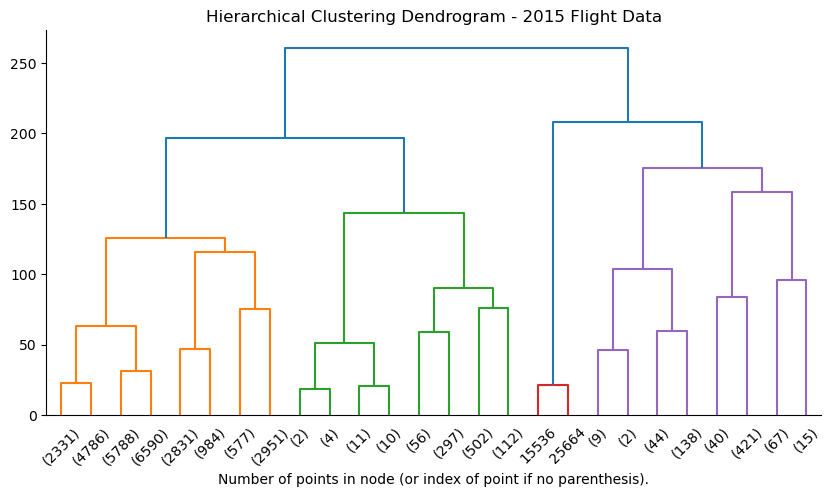

In [264]:
#helper function to plot a dendrogram

def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

#graphing station

plt.figure(figsize=(10, 5))
plt.title("Hierarchical Clustering Dendrogram - 2015 Flight Data")
# plot the top three levels of the dendrogram
plot_dendrogram(ac, truncate_mode="level", p=4)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()

In [266]:
ac_labels

array([3, 3, 0, ..., 3, 3, 3])

In [268]:
supersampled_df['HAC_Cluster'] = ac_labels

In [270]:
supersampled_df.groupby(['HAC_Cluster'])[fwd_vars_C].mean()

,TAXI_OUT,AIR_SYSTEM_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY,DEPARTURE_DELAY
HAC_Cluster,,,,,,
0,0.156298,0.103825,2.580459,4.027649,1.366935,4.328817
1,2.503852,3.422639,0.069202,0.019906,0.010831,0.657404
2,2.919747,2.390940,-0.160111,1.596372,103.226910,25.839316
3,-0.105563,-0.137062,-0.075305,-0.102226,-0.048038,-0.146675


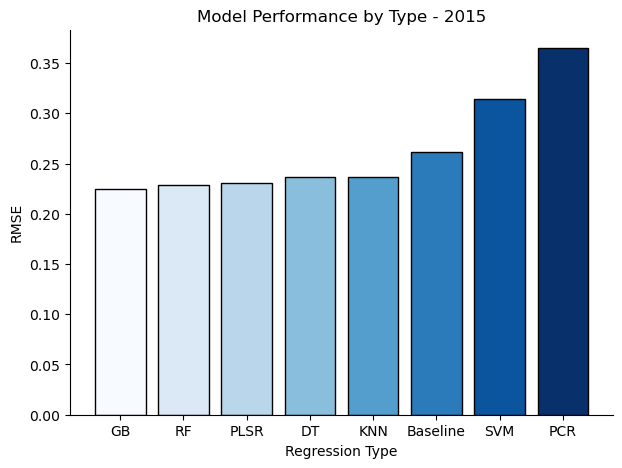

In [288]:
#graping station - 2015, ALL models

regs = ['Baseline','PCR', 'PLSR', 'DT', 'SVM', 'RF', 'KNN', 'GB']

rmses = [0.262, 0.365, 0.231, 0.237, 0.3147, 0.229, 0.237, 0.225]

data = {'Regressions': regs, 'RMSE': rmses}

df = pd.DataFrame(data)

# Sort DataFrame by the 'Values' column (Use ascending=False for descending order)
df_sorted = df.sort_values('RMSE', ascending=True)

cmap = plt.get_cmap('Blues')
colors = cmap(np.linspace(0, 1, len(regs)))

# Plot the sorted data
plt.figure(figsize=(7, 5))
plt.bar(df_sorted['Regressions'], df_sorted['RMSE'], color = colors, edgecolor = 'black')
plt.xlabel('Regression Type')
plt.ylabel('RMSE')
plt.title('Model Performance by Type - 2015')
plt.show()

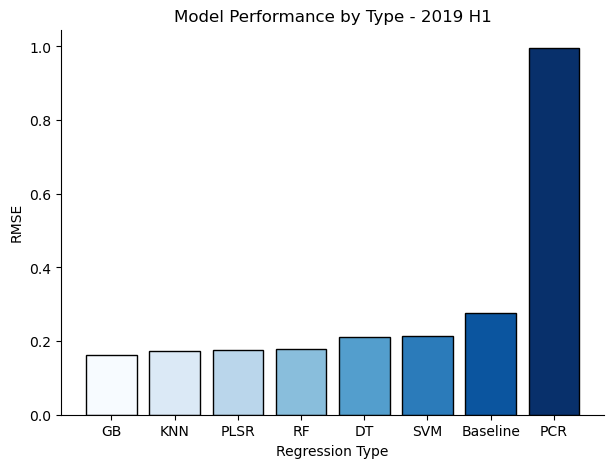

In [290]:
#graping station - 2019 H1, ALL models

regs = ['Baseline','PCR', 'PLSR', 'DT', 'SVM', 'RF', 'KNN', 'GB']

rmses = [0.2759, 0.9955, 0.1748, 0.211, 0.2129, 0.178, 0.173, 0.162]

data = {'Regressions': regs, 'RMSE': rmses}

df = pd.DataFrame(data)

# Sort DataFrame by the 'Values' column (Use ascending=False for descending order)
df_sorted = df.sort_values('RMSE', ascending=True)

cmap = plt.get_cmap('Blues')
colors = cmap(np.linspace(0, 1, len(regs)))

# Plot the sorted data
plt.figure(figsize=(7, 5))
plt.bar(df_sorted['Regressions'], df_sorted['RMSE'], color = colors, edgecolor = 'black')
plt.xlabel('Regression Type')
plt.ylabel('RMSE')
plt.title('Model Performance by Type - 2019 H1')
plt.show()

<h3>Conclusions</h3>

For the gradient boosting model and the clustering algorithms, we're going to use a sampled dataset for the 2015 data (1. The normal dataset is rocking about 5.8 million rows, and any of the algorithms that needed to be done for Milestone 2 will crash the kernel if we don't scale down. 

- K Neighbors: Regular Sample (10% of data)
- Gradient Boost: Regular Sample (10% of data)
- K-Means: Regular Sample (10% of data)
- DBSCAN + HAC: Super Sample (0.5% of data)

WEEK 8:

- After standard scaling the data, we ran a grid search on the 2015 data (5 forward-selected variables: 'TAXI_OUT', 'AIR_SYSTEM_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY') with Repeated K-Fold cross-validation to determine the optimal number of neighbors for the KNeighbors model. The grid search results showed an optimal mean CV RMSE of 0.238 (as shown by the scatterplot). Implements a bit of the Elbow Rule
- After determining the optimal K, we ran a final KNeighbors model with n_neighbors = 13. The test RMSE came out as 0.237, which is ever so slightly better than the training RMSE, but indicative that we likely did not overfit the model to the data
  
WEEK 9:

- After standard scaling the data, we ran a randomized search on the 2015 data (5 forward-selected variables: 'TAXI_OUT', 'AIR_SYSTEM_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY') with Repeated K-Fold cross-validation to determine the optimal number of learning_rate, n_estimators, and max_depth for the GradientBoostingRegressor model. The HistGradientBoostingRegressor model handles larger datasets faster, but we can't tune the n_estimators hyperparameter if we use that model. So we'll keep it simple. The best set of parameters gave a mean CV RMSE of 0.2245, which is probably the best we've seen so far on this dataset, and better than the random forest model (similar to 2019)
- Regularization is done by tuning the "min_samples_leaf" parameter. We got an optimal value at 1
- After determining the optimal K, we ran a final GradientBoostingRegressorModel with our optimized hyperparameters (learning_rate=0.15, max_depth=4, min_samples_leaf=1, n_estimators=105). The test RMSE came out to 0.225, about the same our CV RMSE (but not so drastic as to suggest overfitting) and the best we've seen so far on the 2015 data
- Feature importances appear to be almost identical to that of the random forest model for 2015

WEEK 10:

- After splitting the 2015 data up into train and test sets and standard scaling the data, the first K-Means model we ran used the 5 forward-selected variables from the previous weeks and the target ('TAXI_OUT', 'AIR_SYSTEM_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY') as the basis of the clustering algorithm
- From our experiments on the 2019 H1 data, we immediately used mini-batch K-means on the 2015 data. Mini-batch K-Means uses small, random samples (mini-batches) in each iteration. This drastically cuts down computation time while yielding results nearly identical to standard K-Means, and we ran ours with samples of 2000 with an initial K of 2 clusters
- After running the mini-batch K-means, we got a silhouette score of 0.8135. The next step was to optimize K for our equation. We used the elbow method technique to select k = 5 after making a graph of the within-cluster sum of squares (WCSS), the and the number of cluster K
- After using k = 5, the silhouette score came out to be about 0.4718, which is a good bit worse but still indicative of the samples in one cluster being far away from neighboring clusters AND similar to the same silhouette score of the 2019 H1 data
- We used Euclidean distance because the centroid minimizes the sum of squared distances only with this metric
- The last thing we did was profile our clusters via a means report. The cluster with the highest average DEPARTURE_DELAY value also had the largest average values for WEATHER_DELAY and AIRLINE_DELAY. The actual values are Z-scores so there's not too much to pull there, but it's good to see what got grouped together.
  

WEEK 11:

- To tune the DBSCAN for the 2015 data, we ran a super simple grid search of different epsilon and different min_samples. The rule of thumb for overfitting is if 50% or more of the data is classified as noise (-1's), then we gotta pick differently. Also, if epsilon is too high, everything will get grouped into 1 cluster (which is what we saw with the "optimal" values).  The hyperparameters that returned the best silhouette score (0.884) from our test were eps = 1 and min_samples = 10, but it looks like this set clustered almost the entire dataset together. To mitigate this, we experimented with lowering the epsilon value and raising min_samples. The final model we tried (silhouette score = 0.433) had eps = 0.4 and min_samples = 10. 3 new clusters were created, and the noise increased but it looks like we were able to break up the blob of points just in a similar fashion to the 2019 H1 data sample.
- We used an HAC model on the same sample of data to see if we got something any different. It looks like the main point of modularity is the linkage method you use for the model. This can be single, complete, average, or Ward. Our first model used 4 clusters and Ward linkage, and the silhouette score came back as a 0.37.
- It looks like the main way to tune this model is to adjust the number of clusters or change the linkage method. Using Ward linkage gave us the lowest silhouette score (albeit still positive), but the rest basically put all the points in 1 cluster on the dendrogram. So it looks like Ward linkage is the way we'll take for this model; Ward linkage minimizes the variance of the clusters being merged and doesn't seem to be sensitive to outliers in the data (we already standardized it but still). Overall, between all the optimized clustering methods, K-means
- We profiled the data by doing a means report by cluster. Using DBSCAN, the cluster with the highest average DEPARTURE_DELAY value had the highest average LATE_AIRCRAFT_DELAY value (again, we can't make much of the actual values because they're all z-scores). Using HAC, the cluster with the highest average DEPARTURE_DELAY value had the highest WEATHER_DELAY and TAXI_OUT average values. Cool to see what each model prioritizes!

Depth Points:

- The gradient boost is that good. Lowest RMSE across all models for both years
